# AI Sentiment Analyzer — Project 19

**Scenario:** a coffee shop wants to know whether its customer reviews are positive, negative or neutral.

**Stack:** Hugging Face Transformers (pretrained model) + Pandas.

This notebook runs the four student tasks end to end, on CPU, with no API keys:

1. Load sample reviews
2. Use a pretrained sentiment model
3. Classify each review
4. Calculate sentiment counts with Pandas

and ends with the expected output: **a customer feedback analysis report**.

In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")  # hide library notices, keep the output readable

import pandas as pd
import torch
import transformers

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
transformers.logging.set_verbosity_error()

print(
    "pandas",
    pd.__version__,
    "| transformers",
    transformers.__version__,
    "| torch",
    torch.__version__,
)

pandas 2.3.3 | transformers 4.57.6 | torch 2.8.0+cpu


## 1. Load sample reviews

80 English reviews of 8 coffee-shop products. Each one also has a human label (`true_label`) so we can check the model afterwards. `load_reviews` validates the columns, trims text and drops blank or duplicate reviews.

In [2]:
from sentiment_analyzer.data_loader import load_reviews

reviews = load_reviews(ROOT / "data" / "sample_reviews.csv")
print(f"{len(reviews)} reviews loaded, {reviews.attrs['rows_dropped']} dropped")
reviews.head()

80 reviews loaded, 0 dropped


,review_id,date,product,rating,review_text,true_label
0,1,2026-08-01,Latte,4,Silky milk and a deep espresso flavor. I would...,positive
1,2,2026-11-01,Latte,5,Lovely foam and exactly the right temperature.,positive
2,3,2026-10-01,Latte,4,The barista made it with oat milk and it taste...,positive
3,4,2026-09-01,Latte,5,The vanilla latte was subtle and wonderfully s...,positive
4,5,2026-08-02,Latte,4,I did not expect to love the lavender flavor t...,positive


In [3]:
reviews["product"].value_counts()

product
Latte        10
Espresso     10
Cold Brew    10
Croissant    10
Bagel        10
Matcha       10
Muffin       10
Sandwich     10
Name: count, dtype: int64

## 2. Use a pretrained sentiment model

[`cardiffnlp/twitter-roberta-base-sentiment-latest`](https://huggingface.co/cardiffnlp/twitter-roberta-base-sentiment-latest) is a RoBERTa model already fine-tuned for 3-class sentiment (negative / neutral / positive). We do not train anything: we load it with the Transformers `pipeline` API. The first run downloads it (~500 MB); after that it is cached.

In [4]:
from transformers import pipeline

MODEL_NAME = "cardiffnlp/twitter-roberta-base-sentiment-latest"
sentiment_model = pipeline("text-classification", model=MODEL_NAME, device=-1)  # CPU
sentiment_model.model.config.id2label

{0: 'negative', 1: 'neutral', 2: 'positive'}

A quick sanity check on three hand-written reviews:

In [5]:
sentiment_model(
    [
        "Best croissant I have had in years!",
        "The latte was okay, nothing special.",
        "Waited 25 minutes and the coffee was cold.",
    ]
)

[{'label': 'positive', 'score': 0.9856023192405701},
 {'label': 'neutral', 'score': 0.5360333323478699},
 {'label': 'negative', 'score': 0.713083803653717}]

## 3. Classify each review

All 80 reviews go through the model in batches. For each one we keep the predicted label and the model's confidence (probability of that label).

In [6]:
from time import perf_counter

start = perf_counter()
outputs = sentiment_model(
    reviews["review_text"].tolist(), batch_size=16, truncation=True, max_length=512
)
elapsed = perf_counter() - start

scored = reviews.assign(
    sentiment=[o["label"].lower() for o in outputs],
    confidence=[round(o["score"], 3) for o in outputs],
)
print(f"Classified {len(scored)} reviews in {elapsed:.1f} s on CPU")
scored[["product", "rating", "review_text", "sentiment", "confidence"]].head(10)

Classified 80 reviews in 0.5 s on CPU


,product,rating,review_text,sentiment,confidence
0,Latte,4,Silky milk and a deep espresso flavor. I would...,positive,0.815
1,Latte,5,Lovely foam and exactly the right temperature.,positive,0.977
2,Latte,4,The barista made it with oat milk and it taste...,positive,0.975
3,Latte,5,The vanilla latte was subtle and wonderfully s...,positive,0.964
4,Latte,4,I did not expect to love the lavender flavor t...,positive,0.876
5,Latte,3,It tasted like the latte I usually get here.,neutral,0.780
6,Latte,3,The milk and espresso were both noticeable.,neutral,0.806
7,Latte,3,"It was a standard latte, about what I expected.",neutral,0.845
8,Latte,1,The milk tasted scorched and left a bitter aft...,negative,0.839
9,Latte,2,This was lukewarm by the time it reached the t...,negative,0.677


## 4. Calculate sentiment counts with Pandas

Overall counts and percentages, then a breakdown by product and by month.

In [7]:
LABELS = ["positive", "neutral", "negative"]
counts = scored["sentiment"].value_counts().reindex(LABELS, fill_value=0)
summary = pd.DataFrame(
    {
        "reviews": counts,
        "percent": (counts / len(scored) * 100).round(1),
        "avg_confidence": scored.groupby("sentiment")["confidence"].mean().reindex(LABELS).round(3),
    }
)
summary

,reviews,percent,avg_confidence
sentiment,,,
positive,41,51.2,0.871
neutral,21,26.2,0.767
negative,18,22.5,0.763


In [8]:
by_product = pd.crosstab(scored["product"], scored["sentiment"]).reindex(
    columns=LABELS, fill_value=0
)
by_product["% positive"] = (by_product["positive"] / by_product.sum(axis=1) * 100).round(0)
by_product.sort_values("% positive", ascending=False)

sentiment,positive,neutral,negative,% positive
product,,,,
Matcha,7,2,1,70.0
Bagel,6,3,1,60.0
Cold Brew,6,2,2,60.0
Croissant,5,2,3,50.0
Espresso,5,3,2,50.0
Latte,5,3,2,50.0
Muffin,5,4,1,50.0
Sandwich,2,2,6,20.0


In [9]:
by_month = pd.crosstab(
    scored["date"].dt.strftime("%Y-%m").rename("month"), scored["sentiment"]
).reindex(columns=LABELS, fill_value=0)
by_month

sentiment,positive,neutral,negative
month,,,
2026-08,9,5,2
2026-09,10,5,2
2026-10,11,7,13
2026-11,11,4,1


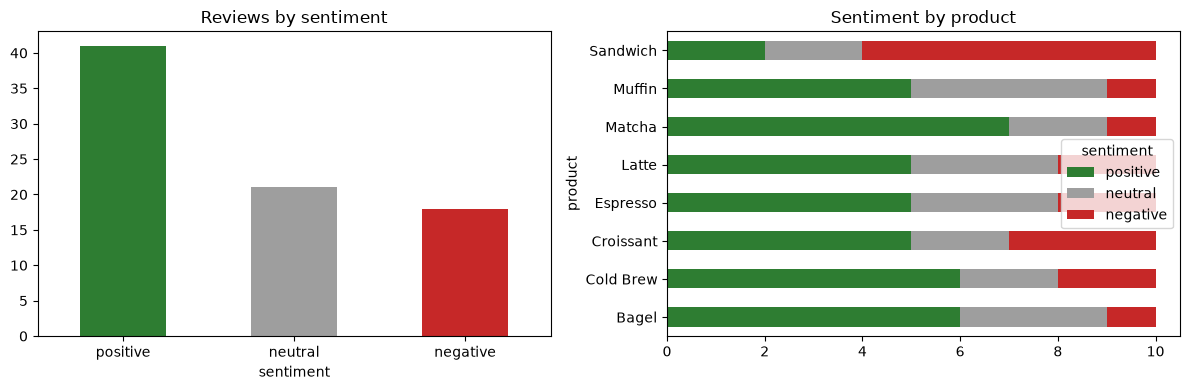

In [10]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
colors = ["#2e7d32", "#9e9e9e", "#c62828"]
counts.plot.bar(ax=ax1, color=colors, rot=0, title="Reviews by sentiment")
by_product[LABELS].plot.barh(ax=ax2, stacked=True, color=colors, title="Sentiment by product")
plt.tight_layout()

### How good is the model?

Because each sample review has a human label, we can measure accuracy and see which classes the model confuses.

In [11]:
accuracy = (scored["sentiment"] == scored["true_label"]).mean()
print(f"Accuracy vs human labels: {accuracy:.1%}")
pd.crosstab(
    scored["true_label"], scored["sentiment"], rownames=["human"], colnames=["model"]
).reindex(index=LABELS, columns=LABELS, fill_value=0)

Accuracy vs human labels: 86.2%


model,positive,neutral,negative
human,,,
positive,35,2,0
neutral,4,16,0
negative,2,3,18


In [12]:
wrong = scored.loc[
    scored["sentiment"] != scored["true_label"],
    ["review_text", "true_label", "sentiment", "confidence"],
]
wrong

,review_text,true_label,sentiment,confidence
27,"The drink was strong, which may suit some people.",neutral,positive,0.701
47,I liked the spread but the bagel was a little ...,neutral,positive,0.615
49,The kitchen sent a plain bagel after I ordered...,negative,neutral,0.859
56,The matcha was stronger than the latte and lig...,neutral,positive,0.674
57,The powder collected in lumps at the bottom.,negative,neutral,0.875
59,"Great, a lovely green drink that tastes just l...",negative,positive,0.979
60,The blueberry muffin had real berries in every...,positive,neutral,0.580
63,It was still warm and the chocolate pieces wer...,positive,neutral,0.702
67,"The cake was a bit dense, but the topping was ...",neutral,positive,0.866
69,"Wonderful, another blueberry muffin with exact...",negative,positive,0.984


## Expected output: customer feedback analysis report

The project's pipeline (`python -m sentiment_analyzer.cli`) does the same steps and writes the full report to `reports/feedback_report.md`, plus `web/data/report.json` for the static site. Here we generate it from the notebook and print it.

In [13]:
from IPython.display import Markdown

from sentiment_analyzer.cli import generate_report

generate_report(ROOT / "data" / "sample_reviews.csv", ROOT / "web" / "data", ROOT / "reports")
Markdown(
    (ROOT / "reports" / "feedback_report.md")
    .read_text(encoding="utf-8")
    .replace("](charts/", "](../reports/charts/")
)

# Bean & Leaf customer feedback report

Analyzed **80** reviews after dropping **0** blank or duplicate rows.

Model **cardiffnlp/twitter-roberta-base-sentiment-latest** · Generated 2026-11-22T13:24:40+00:00

## Sentiment breakdown

| Sentiment | Count | Share | Mean confidence |
| --- | ---: | ---: | ---: |
| Positive | 41 | 51.2% | 87.1% |
| Neutral | 21 | 26.2% | 76.7% |
| Negative | 18 | 22.5% | 76.3% |

## Sentiment by product

| Product | Positive | Neutral | Negative |
| --- | ---: | ---: | ---: |
| Bagel | 6 | 3 | 1 |
| Cold Brew | 6 | 2 | 2 |
| Croissant | 5 | 2 | 3 |
| Espresso | 5 | 3 | 2 |
| Latte | 5 | 3 | 2 |
| Matcha | 7 | 2 | 1 |
| Muffin | 5 | 4 | 1 |
| Sandwich | 2 | 2 | 6 |

## Monthly trend

| Month | Positive | Neutral | Negative |
| --- | ---: | ---: | ---: |
| 2026-08 | 9 | 5 | 2 |
| 2026-09 | 10 | 5 | 2 |
| 2026-10 | 11 | 7 | 13 |
| 2026-11 | 11 | 4 | 1 |

## What customers love

- “This was the best plain croissant I have had all month.” (review 35, 98.6% model confidence)
- “Wonderful, another blueberry muffin with exactly one blueberry.” (review 70, 98.4% model confidence)
- “I loved the peppery greens and the warm sourdough.” (review 72, 97.9% model confidence)

## What customers complain about

- “The bread was soggy and the filling was bland.” (review 75, 90.7% model confidence)
- “The new kitchen crew gave me the wrong sandwich twice.” (review 78, 90.5% model confidence)
- “It was so dry that I could not finish it.” (review 49, 88.6% model confidence)

## Evaluation

The model matched **86.2%** of the hand labels. It classified **21.7%** of 1–2 star reviews as positive or neutral.

| Reference / Predicted | Positive | Neutral | Negative |
| --- | ---: | ---: | ---: |
| Positive | 35 | 2 | 0 |
| Neutral | 4 | 16 | 0 |
| Negative | 2 | 3 | 18 |

### Misclassified reviews

- Review 28, Cold Brew (neutral → positive): “The drink was strong, which may suit some people.”
- Review 48, Bagel (neutral → positive): “I liked the spread but the bagel was a little tough.”
- Review 50, Bagel (negative → neutral): “The kitchen sent a plain bagel after I ordered sesame.”
- Review 57, Matcha (neutral → positive): “The matcha was stronger than the latte and lighter than the espresso.”
- Review 58, Matcha (negative → neutral): “The powder collected in lumps at the bottom.”
- Review 60, Matcha (negative → positive): “Great, a lovely green drink that tastes just like dishwater.”
- Review 61, Muffin (positive → neutral): “The blueberry muffin had real berries in every bite.”
- Review 64, Muffin (positive → neutral): “It was still warm and the chocolate pieces were melting.”
- Review 68, Muffin (neutral → positive): “The cake was a bit dense, but the topping was nice.”
- Review 70, Muffin (negative → positive): “Wonderful, another blueberry muffin with exactly one blueberry.”
- Review 76, Sandwich (negative → neutral): “I found an unripe tomato stem in the middle of my sandwich.”

## Limitations

The English model was trained on tweets. Sarcasm and mixed reviews can be difficult.
Accuracy describes this small, fictional dataset.
